# **Project: Predict Student Performance**

**Objective:**
 **Learn Regression Model (Scikit-Learn).**

**Install and import the required Python libraries**

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

**include Importent libraries**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

**Load datasets**

In [3]:
maths = pd.read_excel("Maths.csv", engine="openpyxl")
portuguese = pd.read_excel("Portuguese.csv", engine="openpyxl")

In [4]:
print("Maths dataset shape:", maths.shape)
print("Portuguese dataset shape:", portuguese.shape)

Maths dataset shape: (397, 33)
Portuguese dataset shape: (651, 33)


In [5]:
display(maths.head())

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## **Understand the dataset**

In [6]:
print("Maths columns:")
print(maths.columns.tolist())

print("\nPortuguese columns:")
print(portuguese.columns.tolist())

print("\nMaths dataset information:")
maths.info()

print("\nPortuguese dataset information:")
portuguese.info()

Maths columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Portuguese columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Maths dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      397 non-null    object
 1   sex         397 non-null    object
 2   age       

**Statistical Summary**

In [8]:
display(maths.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,397,2,GP,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,397,2,F,209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,397.0,NaN,NaN,NaN,16.70529,1.279716,15.0,16.0,17.0,18.0,22.0
address,397,2,U,308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,397,2,GT3,283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,397,2,T,355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,397.0,NaN,NaN,NaN,2.748111,1.097301,0.0,2.0,3.0,4.0,4.0
Fedu,397.0,NaN,NaN,NaN,2.521411,1.090672,0.0,2.0,2.0,3.0,4.0
Mjob,397,5,other,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,397,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
display(portuguese.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,651,2,GP,424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,651,2,F,385,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,651.0,NaN,NaN,NaN,16.745008,1.217609,15.0,16.0,17.0,18.0,22.0
address,651,2,U,453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,651,2,GT3,459,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,651,2,T,570,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,651.0,NaN,NaN,NaN,2.516129,1.134481,0.0,2.0,2.0,4.0,4.0
Fedu,651.0,NaN,NaN,NaN,2.308756,1.100308,0.0,1.0,2.0,3.0,4.0
Mjob,651,5,other,259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,651,5,other,368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Clean the data**

In [10]:
print("Maths missing values:")
print(maths.isnull().sum())

Maths missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [11]:
print("\nPortuguese missing values:")
print(portuguese.isnull().sum())


Portuguese missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [12]:
print("\nMaths duplicate rows:", maths.duplicated().sum())
print("Portuguese duplicate rows:", portuguese.duplicated().sum())


Maths duplicate rows: 2
Portuguese duplicate rows: 2


In [13]:
maths = maths.drop_duplicates().dropna(subset=["G3"]).copy()
portuguese = portuguese.drop_duplicates().dropna(subset=["G3"]).copy()

print("Clean Maths shape:", maths.shape)
print("Clean Portuguese shape:", portuguese.shape)

Clean Maths shape: (395, 33)
Clean Portuguese shape: (649, 33)


**Combine the two datasets**

In [16]:
maths["course"] = "Maths"
portuguese["course"] = "Portuguese"

students = pd.concat(
    [maths, portuguese],
    ignore_index=True
)

print("Combined dataset shape:", students.shape)
display(students.head())
display(students.tail())

Combined dataset shape: (1044, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,course
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,Maths
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,Maths
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,Maths
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,Maths
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,Maths


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,course
1039,MS,F,19,R,GT3,T,2,3,services,other,...,4,2,1,2,5,4,10,11,10,Portuguese
1040,MS,F,18,U,LE3,T,3,1,teacher,services,...,3,4,1,1,1,4,15,15,16,Portuguese
1041,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,5,6,11,12,9,Portuguese
1042,MS,M,17,U,LE3,T,3,1,services,services,...,4,5,3,4,2,6,10,10,10,Portuguese
1043,MS,M,18,R,LE3,T,3,2,services,other,...,4,1,3,4,5,4,10,11,11,Portuguese


**course distribution**

In [17]:
print(students["course"].value_counts())

course
Portuguese    649
Maths         395
Name: count, dtype: int64


# **Perform exploratory data analysis (EDA)**

**final grade distribution**

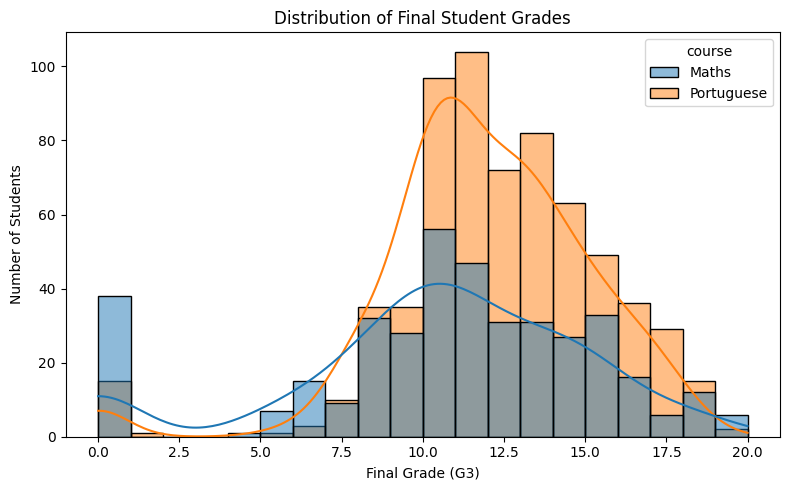

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=students,
    x="G3",
    hue="course",
    bins=20,
    kde=True
)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

X-axis (Final Grade G3): The final grade achieved by students, ranging from 0 to 20.



Y-axis (Number of Students): The number of students whose grades fall within each interval.



Bars: Taller bars mean more students received grades within that interval.



Bins = 20: The grade range is divided into 20 intervals to display the distribution.



KDE = True: Adds a smooth curve to help visualize the distribution.

The visualization provides an initial understanding of student academic performance in Maths and Portuguese. Most observed grades are concentrated in the middle range, while some students have very low or high grades. Further analysis is required to investigate the grade-zero observations and compare the subjects fairly. This analysis can help guide the next stage of the project, which involves predicting final student grades using a Linear Regression model.

**Compare Maths and Portuguese grades**

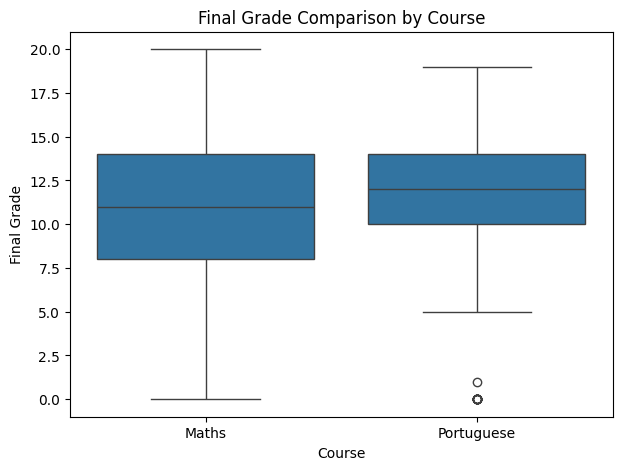

In [19]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=students,
    x="course",
    y="G3"
)

plt.title("Final Grade Comparison by Course")
plt.xlabel("Course")
plt.ylabel("Final Grade")
plt.show()

**Study time versus final grade**

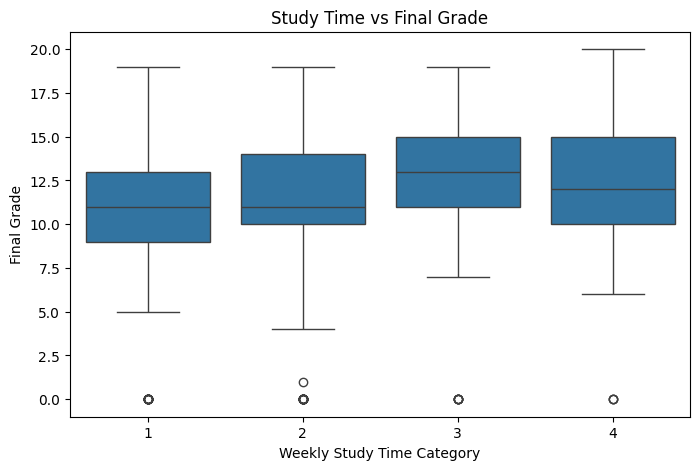

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=students,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade")
plt.show()

The visualization suggests that students reporting 5–10 hours of weekly study time have the highest median final grade among the four categories. However, students' grades vary considerably within each category, and studying for more than 10 hours does not correspond to a higher median grade in this dataset. Therefore, study time should be considered alongside other academic and personal factors when analyzing student performance.

**Previous failures versus final grade**

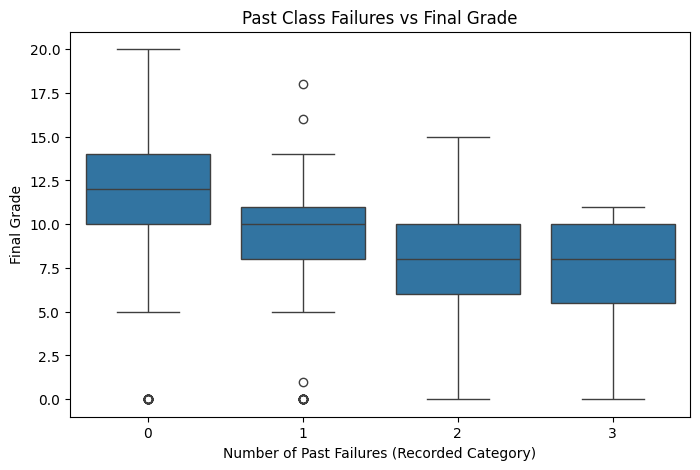

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=students,
    x="failures",
    y="G3"
)

plt.title("Past Class Failures vs Final Grade")
plt.xlabel("Number of Past Failures (Recorded Category)")
plt.ylabel("Final Grade")
plt.show()

**Correlation heatmap**

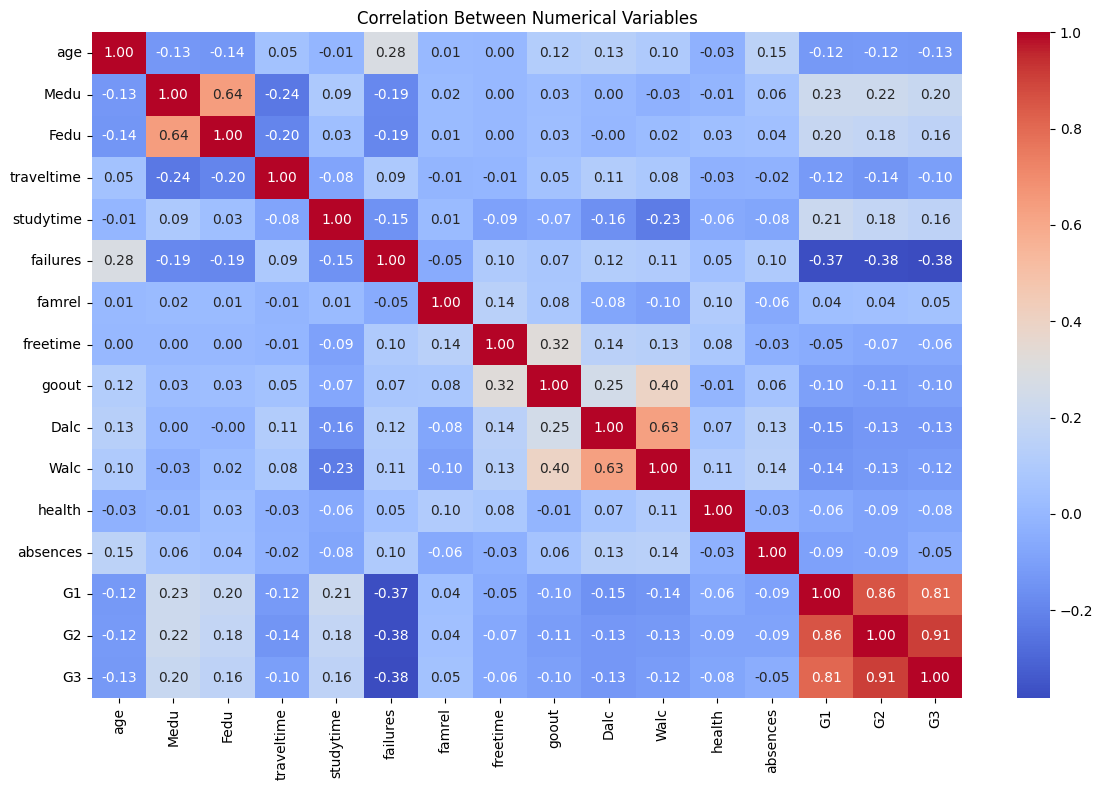

In [22]:
numeric_data = students.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

G2 has a strong positive correlation with G3 (0.91), while G1 also shows a strong positive correlation with G3 (0.81).

G1 and G2 have a strong positive correlation of 0.86, indicating that students' grades across the two periods tend to move together.

Past class failures have a negative correlation with final grades (-0.38), suggesting that more recorded failures are associated with lower final grades.

Mother's and father's education levels show a positive correlation of 0.64.

Workday and weekend alcohol consumption have a positive correlation of 0.63.

Study time has a weak positive correlation with final grades (0.16), whereas absences have a very weak negative correlation (-0.05).

**Prepare the features for machine learning**

Our target is G3, the final grade.
- X (features): Information used to make the prediction.
- y (target): The final grade we want to predict.
We will use G1 and G2, which are earlier-period grades, as predictors. This is a useful baseline model when those grades are already available.

Categorical variables such as **school**, **sex**, **Mjob** and **Fjob** must be encoded into numerical features. We will use OneHotEncoder so that categories are represented appropriately.

In [23]:
# Separate features and target
X = students.drop(columns=["G3"])
y = students["G3"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target variable: G3")

Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'course']
Target variable: G3


**Split the data into training and testing sets**

We use **80%** of the data for training and **20%** for testing. The test set is held back to evaluate predictions on unseen rows.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 835
Testing rows: 209


**Build the Linear Regression model**

In [25]:
# Preprocess the numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Create the machine learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


**Predict the final grades**

In [26]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": y_pred.round(2)
})

display(results.head(10))

,Actual Grade,Predicted Grade
0,11,10.47
1,8,8.22
2,13,14.33
3,11,11.04
4,12,12.27
5,11,12.55
6,0,5.57
7,11,10.43
8,15,14.65
9,13,13.40


The comparison of actual and predicted grades provides an initial assessment of the model's performance. Although some predictions are close to the actual values, others show noticeable errors. Therefore, evaluation using metrics such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²) is necessary to assess the model's overall performance on the test dataset.

**Evaluate model performance**

In [27]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")
print(f"R-squared (%): {r2 * 100:.2f}%")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 1.02
Mean Squared Error (MSE): 3.10
Root Mean Squared Error (RMSE): 1.76
R-squared (R²): 0.7997
R-squared (%): 79.97%


**Visualize actual versus predicted grades**

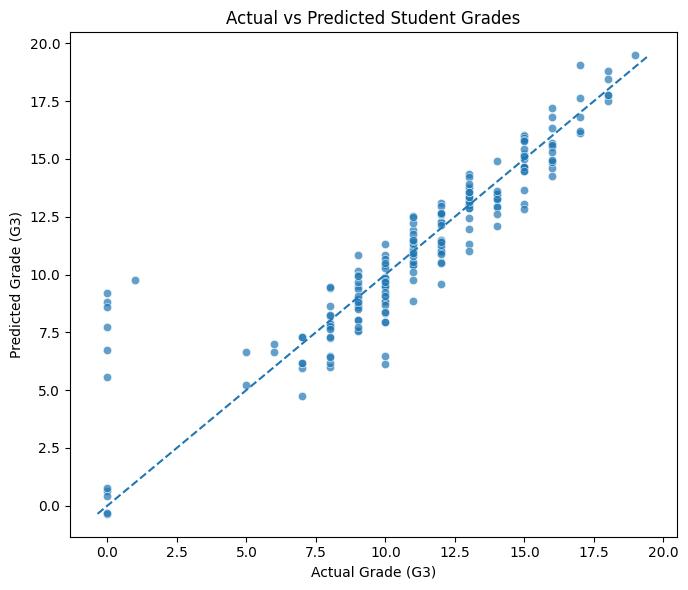

In [28]:
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.7
)

# Reference line for perfect predictions
min_grade = min(y_test.min(), y_pred.min())
max_grade = max(y_test.max(), y_pred.max())

plt.plot(
    [min_grade, max_grade],
    [min_grade, max_grade],
    linestyle="--"
)

plt.title("Actual vs Predicted Student Grades")
plt.xlabel("Actual Grade (G3)")
plt.ylabel("Predicted Grade (G3)")
plt.tight_layout()
plt.show()

**Predict a grade for a new student**

In [29]:
# Take one test student
sample_student = X_test.iloc[[0]]

# Predict their final grade
predicted_grade = model.predict(sample_student)[0]

print("Predicted final grade:", round(predicted_grade, 2))
print("Actual final grade:", y_test.iloc[0])

Predicted final grade: 10.47
Actual final grade: 11


The objective of this project was to analyze student performance using the Maths and Portuguese datasets and develop a Linear Regression model to predict final grades (G3).

The project included data loading, data cleaning, exploratory data analysis, data visualization, feature preparation, train-test splitting, and model evaluation.

The model was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R-squared (R²) score. The results help assess how closely the predicted grades match the actual grades.

The visualizations were used to explore relationships between final grades and variables such as study time, past failures, and course subject.

This project provided practical experience in Python, Pandas, Seaborn, Matplotlib, and Scikit-learn. Future improvements could include comparing Linear Regression with Random Forest Regression and evaluating the models using cross-validation.